# 3-servo: window term

Fit the window term of mg90-d's current reading from 105 OpenLoop onsets from rest, so the board's field `g_window_q016` carries a measured value. Stage 5's cruise-friction notebook refits the velocity loop's friction line on top of it.

## Purpose

The board reads the motor current once a PWM period, at the crest sample, 31 timer ticks after the counter's crest and inside the drive's on-window. That sample is not the winding's mean current over the period. Two things lift it. The current rises through the on-window, so a sample taken after the window's middle reads above the period's mean. And part of what the shunt sees during the on-window never reaches the winding's flux. Stage 3's resistance notebook held the servo at six levels with a meter in series and fitted the crest over the meter's mean as a conductance times the volts across the inductance, $(1 - D)\,V_\mathrm{on}$, 4.75 mS.

The symbols, each with its spoken name once. $D$ ("D") is the duty, the on-window's share of the period. $V_\mathrm{on}$ ("V on") is the terminal volts while the drive is on. $L$ and $R$ are the winding's inductance and resistance, $\tau = L/R$ ("tau") its time constant. $g$ ("g") is the loss conductance. Read period $k$ is the $k$-th PWM period after the drive leaves rest. The reading of period $k$ is modeled as

$$y_k = i_w(k;\,L, R) + g\,(1 - D_k)\,V_\mathrm{on},$$

where $i_w$ ("i w") is the winding's current at the sample's instant, built pulse by pulse from rest. This $g$ is the loss term alone, since the model places the sample at its own instant. What a consumer of the reading wants is the period's mean current, so the field takes $g$ plus the sample's lateness, the part of the reading the sample's place after the window's middle adds in a settled period, in the same $(1 - D)\,V_\mathrm{on}$ form.

The current loop, the velocity loop's friction feed-forward and the current limits all read the same corrected current. With the field at 0 every reading carries the whole term, about 18 mA at the floor's first width on 5 V.

Onsets from rest are the experiment because the winding starts empty. Its current over the first pulses is small and follows from $L$ and $R$ alone, so the term is a large share of the first readings and the only part with the shape $(1 - D)\,V_\mathrm{on}$.

In [1]:
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oscnb import figures, results, scales, servos
from oscnb import windowterm as wt
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo
BOARD_KEY = "dev-v006-2A-D"             # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
DATA = (Path("../../../telemetry") / PAIR / "window-term").resolve()
SESSIONS = {                            # a session: its three sweeps
    "A": [DATA / "onsets-A" / f"ol-{k}" for k in (1, 2, 3)],
    "brake": [DATA / "onsets-A-brake" / f"ol-{k}" for k in (1, 2, 3)]}
for name, folders in SESSIONS.items():
    print(f"session {name}:",
          ", ".join(str(results.rel(p)) for p in folders))

session A: telemetry/mg90-d__dev-v006-2A-D/window-term/onsets-A/ol-1, telemetry/mg90-d__dev-v006-2A-D/window-term/onsets-A/ol-2, telemetry/mg90-d__dev-v006-2A-D/window-term/onsets-A/ol-3
session brake: telemetry/mg90-d__dev-v006-2A-D/window-term/onsets-A-brake/ol-1, telemetry/mg90-d__dev-v006-2A-D/window-term/onsets-A-brake/ol-2, telemetry/mg90-d__dev-v006-2A-D/window-term/onsets-A-brake/ol-3


### Stage 1 values carried in

The current goes through the current-scale result and the terminal volts through the terminal-chain result, both graded on this board. Sample-timing gives the crest sample's instant and the bridge's ON and OFF edge lags on its rail line, and bridge-states the low-side loop that carries the current while the bridge brakes between pulses.

In [3]:
SCALES = scales.load(BOARD_KEY)         # stage 1's lines for this board
CPA = SCALES.counts_per_a               # shunt counts per A, current-scale
VPV = SCALES.terminal_counts_per_v      # tap counts per V, terminal-chain
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
TIMING = SCALES.sample_timing           # sample-timing's result
SAMPLE = TIMING["crest_sample_ticks"]["shunt"]["value"]   # ticks, crest on
R_BRAKE = SCALES.bridge_states["low_side_loop_ohm"]["value"]   # ohm
DIR_COUNTS = SCALES.current_scale["direction_counts"]   # +1 less -1
SCALES.describe()
print(f"shunt sample {SAMPLE:+.0f} ticks from the crest, low-side loop "
      f"{R_BRAKE:.3f} ohm, direction offset {DIR_COUNTS['value']:.2f} "
      f"counts ({DIR_COUNTS['lo']:.2f} to {DIR_COUNTS['hi']:.2f})")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
shunt sample +31 ticks from the crest, low-side loop 0.301 ohm, direction offset 1.21 counts (0.30 to 2.17)


### Stage 3 values carried in

The resistance notebook's series-meter value of the term and the inductance notebook's locked-burst $L$ and $\tau$ are comparisons. Nothing in the fit uses them.

In [4]:
RES = results.read("3-servo", "resistance", pair=PAIR)
IND = results.read("3-servo", "inductance", pair=PAIR)
G_METER = RES["meter_g_ms"]             # mS, the series-meter holds
L_BURST = IND["l_mh"]                   # mH, the locked bursts
TAU_BURST = IND["tau_us"]               # us, the bursts' L/R
BAND = RES["meter_flat_band"]           # the meter's levels
print(f"meter levels {BAND['duty_pct']['lo']:.0f} to "
      f"{BAND['duty_pct']['hi']:.0f} % duty, {BAND['meter_a']['lo'] * 1e3:.0f}"
      f" to {BAND['meter_a']['hi'] * 1e3:.0f} mA")
print(f"meter g {G_METER['value']:.2f} mS ({G_METER['lo']:.2f} to "
      f"{G_METER['hi']:.2f}); burst L {L_BURST['value']:.3f} mH, L/R "
      f"{TAU_BURST['value']:.0f} us ({TAU_BURST['lo']:.0f} to "
      f"{TAU_BURST['hi']:.0f})")

meter levels 16 to 49 % duty, 229 to 356 mA
meter g 4.75 mS (4.52 to 4.97); burst L 0.820 mH, L/R 199 us (186 to 205)


The constants of the method, each with its unit and reason. The gates are the ones the onsets were planned with, the grid is wide enough that no fit lands on its edge (checked below), and the bootstrap's seed makes its bounds repeat.

In [5]:
AFTER = 60          # rows kept after an onset, 3 ms: the zero's trough rows
TAP_GATE = 6        # counts, the largest entry tap difference: no back-EMF
POT_GATE = 6        # counts the pot may move over the first millisecond
ROWS = 40           # rows of each onset's profile drawn and modelled
READ_PERIODS = 12   # rows fitted, the first twelve pulses after rest
V_ROW_MAX = 30      # the last row V_on is averaged to, inside the ramp
L_GRID = np.arange(0.40e-3, 2.0001e-3, 0.01e-3)   # H, the fit's L grid
R_GRID = np.arange(3.0, 7.5001, 0.02)             # ohm, its R grid
BOOT = 2000         # bootstrap draws over the onsets, within direction
SEED = 20261117     # the draws' seed, so the bounds repeat run to run
LATE_TICKS = np.arange(0.0, 40.1, 5.0)   # ticks, a late first pulse
FENCE = 2 ** 25     # the bound on g_window_q016 x r_q12 the field meets

## Procedure

Two sessions on the experiment image, horn free, 5 V from the DPS, the board's window term off (`g_window_q016` 0 on the servo, the dataset's README).

- Session A, `onsets-A`, three sweeps. Each opens with a 500 ms torque-off baseline. Then the runner seeks the horn to a guard and drives rungs of 25, 27 and 29 % in direction +1, three times, then the same in -1, each rung a 300 ms window from rest after 500 ms of coast.
- The braked repeat, `onsets-A-brake`, three sweeps 33 minutes later. Each sweep is one chain of 100 ms drives at the same duties with a 300 ms brake after each, the drives alternating in sign. The tool releases the brake to coast between a brake's burst and the next drive's, about 3 ms before each onset, so every onset of both sessions leaves a coast. The brake's 300 ms against the coast's 500 ms is the difference between the sessions.

Every drive leaves rest on a ramp of drive widths that starts at the floor's first step, 68 ticks, and grows by about 4.6 ticks a row. The first twelve rows of that ramp, widths 68 to 120 ticks, are the read periods the fit uses.

## Data

### meta.json

Each sweep's `meta.json` carries its board's sense block, the plant stamp of the set the servo held, the drive's limits and `r_q12`, the rail read at the start (`vbus_counts`, in tap units), and the schedule. The board is identified from the sense block and checked, and a sweep with dropped rows or a stamp off the live set is refused.

In [6]:
CAPS = {name: [wt.load_sweep(p) for p in folders]
        for name, folders in SESSIONS.items()}
ALL = [(name, cap) for name, caps in CAPS.items() for cap in caps]
BOARD = ALL[0][1]["board"]              # identified from the sense block
ARR, HZ = ALL[0][1]["arr"], ALL[0][1]["hz"]   # half period ticks, rows/s
assert all((c["board"].key, c["arr"], c["hz"]) == (BOARD.key, ARR, HZ)
           for _, c in ALL)
for name, cap in ALL:
    m = cap["meta"]
    print(f"{name:5s} {cap['name']}: {len(cap['rows'])} rows, stamp "
          f"{m['plant']['plant_stamp']}, r_q12 {m['drive']['r_q12']}, "
          f"rail {wt.rail_v(cap):.3f} V, {len(m['schedule'])} steps "
          f"{m['schedule'][:4]}")

A     ol-1: 118000 rows, stamp 0xbe92, r_q12 3725, rail 4.993 V, 9 steps ['25', '27', '29', '25']
A     ol-2: 118000 rows, stamp 0xbe92, r_q12 3725, rail 4.985 V, 9 steps ['25', '27', '29', '25']
A     ol-3: 118000 rows, stamp 0xbe92, r_q12 3725, rail 4.989 V, 9 steps ['25', '27', '29', '25']
brake ol-1: 154000 rows, stamp 0xbe92, r_q12 3725, rail 4.989 V, 36 steps ['25@100', 'brake:300', 'then:-25@100', 'brake:300']
brake ol-2: 154000 rows, stamp 0xbe92, r_q12 3725, rail 4.977 V, 36 steps ['25@100', 'brake:300', 'then:-25@100', 'brake:300']
brake ol-3: 154000 rows, stamp 0xbe92, r_q12 3725, rail 4.985 V, 36 steps ['25@100', 'brake:300', 'then:-25@100', 'brake:300']


### segments.csv

One line per segment. Segment 0 is the torque-off baseline, the rest the rungs in order, with the commanded duty in Q15, the rows streamed and the host's clock at each end. In the braked sweeps every other segment is a brake, commanded to zero.

In [7]:
EX_A, EX_B = CAPS["A"][0], CAPS["brake"][0]   # one sweep of each session
show(EX_A["segs"].reset_index(), n=4)
show(EX_B["segs"].reset_index(), n=4)

,seg,dir,cmd_duty_q15,streamed,samples,t_start,t_end
0,0,0,0,1,10000,1794921244.944,1794921245.448
1,1,1,8191,1,6000,1794921246.976,1794921247.278
2,2,1,8847,1,6000,1794921248.994,1794921249.296
3,3,1,9502,1,6000,1794921251.099,1794921251.400


,seg,dir,cmd_duty_q15,streamed,samples,t_start,t_end
0,0,0,0,1,10000,1794923239.262,1794923239.763
1,1,1,8191,1,2000,1794923241.323,1794923241.424
2,2,1,0,1,6000,1794923241.425,1794923241.726
3,3,1,-8191,1,2000,1794923241.726,1794923241.828


### sweep.csv

One row per control tick at 20 kHz. `duty_counts` is the applied half-width in timer ticks of the 1200 tick half period, signed by the direction. `current_raw` is the crest shunt sample and `current_trough` the shunt sampled in the off-window, both raw ADC counts. `vmotor_a` and `vmotor_b` are the two terminal taps at the crest, `window_valid` whether the window met the board's current floor, `pos` the raw pot. The rows around the first onset of session A, the last two still rows and the first four driven ones.

In [8]:
cols = ["seg", "tick", "cmd_duty_q15", "duty_counts", "window_valid",
        "current_raw", "current_trough", "vmotor_a", "vmotor_b", "pos"]
first = EX_A["rows"]["seg"] == 1        # the first rung of session A
on = EX_A["rows"][first]["duty_counts"].ne(0).idxmax()   # its onset row
show(EX_A["rows"].loc[on - 2:on + 3, cols], n=None)

,seg,tick,cmd_duty_q15,duty_counts,window_valid,current_raw,current_trough,vmotor_a,vmotor_b,pos
10006,1,6,8191,0,0,1214,1217,772,774,414
10007,1,7,8191,0,0,1212,1214,773,774,414
10008,1,8,8191,68,1,1241,1217,1736,625,414
10009,1,9,8191,73,1,1253,1213,1810,621,414
10010,1,10,8191,78,1,1263,1213,1846,620,413
10011,1,11,8191,82,1,1272,1212,1842,619,413


### The settle gain

The board multiplies a crest sample by a settle gain that depends on the drive's width, since the shunt amplifier has not fully settled in a short window. These are the board's own words (`oscnb.boards`, `i_settle_gain`), and the fit applies them to each row by its width as the board does.

In [9]:
widths = np.arange(BOARD.i_settle_start_ticks, 220, 8)  # one width a band
gain = BOARD.settle_gain(widths)
print("settle gain by half-width (ticks: gain):")
print(", ".join(f"{w}: {g:.4f}" for w, g in zip(widths, gain)))

settle gain by half-width (ticks: gain):
40: 1.1334, 48: 1.0774, 56: 1.0480, 64: 1.0351, 72: 1.0267, 80: 1.0214, 88: 1.0185, 96: 1.0150, 104: 1.0136, 112: 1.0118, 120: 1.0102, 128: 1.0087, 136: 1.0077, 144: 1.0065, 152: 1.0052, 160: 1.0040, 168: 1.0031, 176: 1.0022, 184: 1.0017, 192: 1.0012, 200: 1.0005, 208: 1.0000, 216: 1.0000


### One onset

The crest and trough samples and the applied window over the still rows and the first 40 driven rows of session A's first rung. The thing to see is the crest sample stepping up on the first driven row, before the winding can carry much current, while the trough stays at the zero.

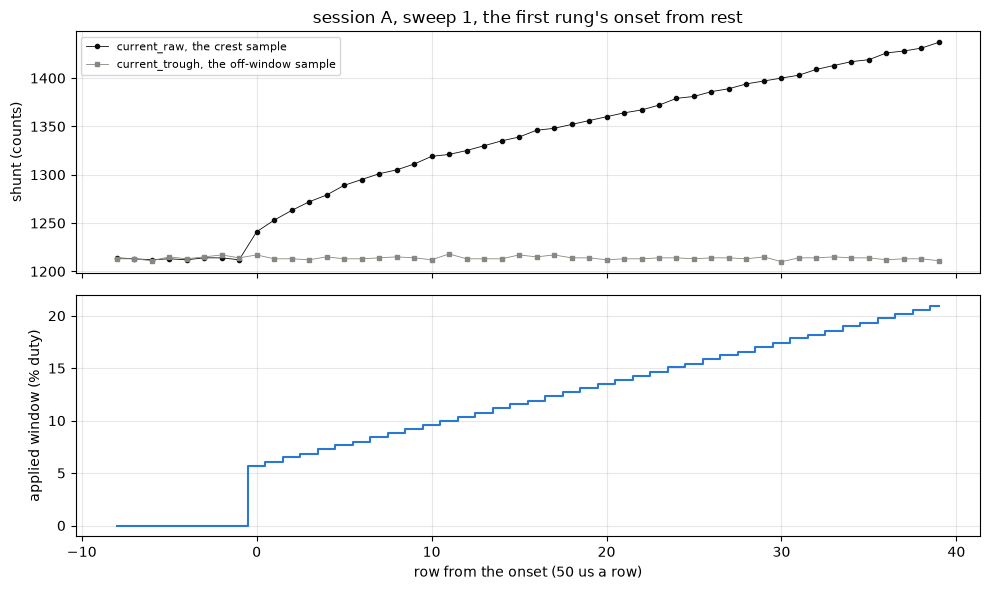

In [10]:
g = EX_A["rows"][EX_A["rows"]["seg"] == 1].reset_index(drop=True)
k0 = int(np.flatnonzero(g["duty_counts"].to_numpy() != 0)[0])
win = g.iloc[:k0 + ROWS]                # the still rows, then the drive
k = np.arange(len(win)) - k0            # rows from the onset
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.plot(k, win["current_raw"], "o-", ms=3, color=INK, lw=0.6,
        label="current_raw, the crest sample")
a1.plot(k, win["current_trough"], "s-", ms=3, color=MUTED, lw=0.6,
        label="current_trough, the off-window sample")
a1.legend(fontsize=8)
figures.label(a1, y="shunt (counts)", title="session A, sweep 1, the first "
              "rung's onset from rest")
a2.step(k, win["duty_counts"] / ARR * 100, where="mid", color=BLUE)
figures.label(a2, x="row from the onset (50 us a row)",
              y="applied window (% duty)")
figures.finish(fig)

The crest sample jumps about 27 counts on the first driven row of a 68 tick pulse into an empty winding and then climbs with the ramp. The trough sample stays within a few counts of the still rows.

## Method

### The onsets and their gates

An onset is the first row of non-zero duty in a drive segment. Its rows run from the segment's first row, the still rows before the drive, to 60 rows after. An onset is kept when it has at least one still row before it with a tap difference of at most 6 counts (no back-EMF at the entry, so the rotor was at rest), the pot moved at most 6 counts over the first millisecond, the drive held one sign over 21 rows, and its ramp is the session's common one.

In [11]:
def catalog(name):
    # every onset of a session's sweeps, gated, named session/sweep
    parts = [wt.onsets(cap, AFTER) for cap in CAPS[name]]
    info = pd.concat([p[1] for p in parts], ignore_index=True)
    info, ramp = wt.gate(info, TAP_GATE, POT_GATE)
    rows = pd.concat([p[0] for p in parts])
    rows = rows.merge(info[["cap", "onset", "sgn", "ok"]],
                      on=["cap", "onset"])
    for frame in (rows, info):
        frame["cap"] = name + "/" + frame["cap"]
    return rows, info.assign(session=name), ramp


CAT = {name: catalog(name) for name in SESSIONS}
for name, (rows, info, ramp) in CAT.items():
    bad = info[~info.ok]
    print(f"session {name}: {len(info)} onsets, {int(info.ok.sum())} kept;"
          f" ramp {list(ramp)}")
    print(f"  dropped: no still row before {int((info.pre_rows < 1).sum())}"
          f", entry tap difference {int((info.pre_vd_max > TAP_GATE).sum())}"
          f", pot moved {int((info.moved > POT_GATE).sum())}, sign "
          f"{int((~info.same_sign).sum())}, another ramp "
          f"{int((info.seq != ramp).sum())}; first window a reading on "
          f"{int(info.valid0.sum())} of {len(info)}")
    print(f"  kept: entry tap difference at most "
          f"{info[info.ok].pre_vd_max.max():.0f}, pot move at most "
          f"{info[info.ok].moved.max():.0f} counts")

session A: 54 onsets, 52 kept; ramp [68, 73, 78, 82, 87, 92, 96, 101, 106, 110, 115, 120, 124, 129]
  dropped: no still row before 2, entry tap difference 0, pot moved 0, sign 0, another ramp 0; first window a reading on 54 of 54
  kept: entry tap difference at most 3, pot move at most 6 counts
session brake: 54 onsets, 53 kept; ramp [68, 73, 78, 82, 87, 92, 96, 101, 106, 110, 115, 120, 124, 129]
  dropped: no still row before 1, entry tap difference 0, pot moved 0, sign 0, another ramp 0; first window a reading on 54 of 54
  kept: entry tap difference at most 6, pot move at most 2 counts


Three onsets of the 108 were dropped, each because its stream opened on the first driven row, which leaves no still row to show the entry was at rest. Every first driven row was a reading.

### Profiles over the zero

Each onset's own zero is the mean trough sample over its rows 0 to 59. Its profile is the crest sample over that zero, row by row. The on-window volts $V_\mathrm{on}$ are the tap difference through terminal-chain, signed by the drive, over the rows at or past the board's terminal floor up to row 30, one value an onset. Each set is fitted at its mean $V_\mathrm{on}$. The sets are session A alone, the braked session alone, and the two pooled.

In [12]:
def onset_set(names):
    # the kept onsets of `names`: ramp, profiles over the zero, V_on
    rows = pd.concat([CAT[n][0] for n in names], ignore_index=True)
    rows = rows[rows.ok].copy()
    rows["h"] = rows["duty_counts"].abs()
    rows["vd"] = (rows["vmotor_a"] - rows["vmotor_b"]) * rows["sgn"]
    drive = rows[rows.k >= 0].sort_values(["cap", "onset", "k"])
    if (drive.groupby("k")["h"].nunique().to_numpy()[:ROWS] != 1).any():
        raise ValueError("the onsets do not share one ramp")
    keys = rows[["cap", "onset", "sgn"]].drop_duplicates().reset_index(
        drop=True)
    by = drive.groupby(["cap", "onset"], sort=False)

    def table(col, n):
        # one onset a line, its first n driven rows
        return np.array([by.get_group((c, o))[col].to_numpy()[:n]
                         for c, o in zip(keys.cap, keys.onset)], float)

    crest, trough = table("current_raw", ROWS), table("current_trough", AFTER)
    h = drive.groupby("k")["h"].mean().to_numpy()[:ROWS]
    vrows = (h >= BOARD.v_window_min_ticks) & (np.arange(ROWS) <= V_ROW_MAX)
    v_on = (table("vd", ROWS)[:, vrows].mean(axis=1) - TAP_OFFSET) / VPV
    rail = float(np.mean([wt.rail_v(c) for n in names for c in CAPS[n]]))
    return SimpleNamespace(names=names, keys=keys, h=h, rail=rail,
                           y=crest - trough.mean(axis=1)[:, None],
                           v_on=v_on, gain=BOARD.settle_gain(h))


SETS = {"A": onset_set(["A"]), "brake": onset_set(["brake"]),
        "pooled": onset_set(["A", "brake"])}
for name, s in SETS.items():
    print(f"{name}: {len(s.y)} onsets ({int((s.keys.sgn > 0).sum())} "
          f"forward), V_on {s.v_on.mean():.3f} V (sd "
          f"{s.v_on.std(ddof=1) * 1e3:.0f} mV), rail {s.rail:.3f} V")
print("ramp, half-widths of the first 13 rows:",
      SETS["pooled"].h[:13].astype(int).tolist())

A: 52 onsets (26 forward), V_on 4.875 V (sd 5 mV), rail 4.989 V
brake: 53 onsets (26 forward), V_on 4.875 V (sd 4 mV), rail 4.983 V
pooled: 105 onsets (52 forward), V_on 4.875 V (sd 5 mV), rail 4.986 V
ramp, half-widths of the first 13 rows: [68, 73, 78, 82, 87, 92, 96, 101, 106, 110, 115, 120, 124]


All three sets read 4.875 V on the terminals with a 5 mV spread over onsets.

### The winding's current from rest

Each pulse is built from its own row's width, a whole pulse. The pulse around crest $k$ conducts from $\mathrm{crest}_k - h_k + t_\mathrm{on}$ to $\mathrm{crest}_k + h_k + t_\mathrm{off}$, with $h_k$ the half-width, $t_\mathrm{on}$ and $t_\mathrm{off}$ ("t on", "t off") stage 1's tap ON and OFF edge lags on its rail line at the sweeps' rail. Inside the pulse the winding charges toward $V_\mathrm{on}/R$ with time constant $L/R$. Between pulses it decays through $R$ plus the low-side loop. The sample closes stage 1's 31 ticks after each crest. The model is linear in $V_\mathrm{on}$, so `oscnb.windowterm.pulse_train` returns the current per volt, and one call fills the whole grid of $L$ and $R$.

In [13]:
def edges(rail, on="value", off="value"):
    # the tap ON and OFF edge lags on stage 1's rail line at `rail`
    (r_lo, v_lo), (r_hi, v_hi) = scales.RAIL_LINE
    f = (rail - v_lo) / (v_hi - v_lo)

    def at(key, end):
        a, b = (TIMING[f"{key}_{r}"][end] for r in (r_lo, r_hi))
        return a + f * (b - a)

    return at("tap_on_edge_lag", on), at("off_edge_lag", off)


L_G, R_G = np.meshgrid(L_GRID, R_GRID, indexing="ij")


def grid(s, lags=None, sample=SAMPLE, first_late=0.0):
    # the winding's current per volt at every row's sample, on the grid
    on, off = edges(s.rail) if lags is None else lags
    return wt.pulse_train(s.h, L_G, R_G, on, off, sample, ARR, HZ,
                          R_BRAKE, first_late)


for s in SETS.values():
    s.lags = edges(s.rail)
    s.F = grid(s)
    print(f"{'+'.join(s.names)}: ON {s.lags[0]:.1f}, OFF {s.lags[1]:.1f} "
          f"ticks at {s.rail:.3f} V")

A: ON 38.7, OFF 13.7 ticks at 4.989 V
brake: ON 38.7, OFF 13.7 ticks at 4.983 V
A+brake: ON 38.7, OFF 13.7 ticks at 4.986 V


### The fit

At every $(L, R)$ of the grid the reading less the winding is linear in $g$, so $g$ comes in closed form there. The cell with the least squares over read periods 1 to 12 is the fit. The reading is the profile times the settle gain by the row's width, over the shunt's counts per A. The rms divides by 9 degrees of freedom, twelve periods less $g$, $L$ and $R$.

In [14]:
def fit(s, y_counts, v_on, F=None, first=0, rows=READ_PERIODS):
    # g, L, R and the rms of a mean profile: g in closed form at every
    # (L, R) of the grid, the cell of least squares kept
    F = s.F if F is None else F
    y = y_counts * s.gain / CPA                    # A, settle gain on
    iw = v_on * F                                  # A, winding at sample
    x = ((1 - s.h / ARR) * v_on)[:, None, None]    # V, the term's lever
    r = y[:, None, None] - iw
    ks = slice(first, rows)
    g = (r[ks] * x[ks]).sum(0) / (x[ks] ** 2).sum(0)
    sse = ((r - g * x)[ks] ** 2).sum(0)
    at = np.unravel_index(np.argmin(sse), sse.shape)
    edge = at[0] in (0, len(L_GRID) - 1) or at[1] in (0, len(R_GRID) - 1)
    cut = (slice(None),) + at
    return {"g": g[at], "L": L_G[at], "R": R_G[at], "edge": edge,
            "rms": np.sqrt(sse[at] / (rows - first - 3)), "y": y,
            "iw": iw[cut], "x": x[:, 0, 0], "res": (r - g * x)[cut]}


HEAD = {name: fit(s, s.y.mean(axis=0), s.v_on.mean())
        for name, s in SETS.items()}
for name, f in HEAD.items():
    assert not f["edge"], name
    print(f"{name:6s} {len(SETS[name].y):3d} onsets: g {f['g'] * 1e3:.3f} "
          f"mS, L {f['L'] * 1e3:.2f} mH, R {f['R']:.2f} ohm, L/R "
          f"{f['L'] / f['R'] * 1e6:.0f} us, rms {f['rms'] * 1e3:.2f} mA")

A       52 onsets: g 3.865 mS, L 0.79 mH, R 4.40 ohm, L/R 180 us, rms 0.40 mA
brake   53 onsets: g 3.804 mS, L 0.80 mH, R 4.36 ohm, L/R 183 us, rms 0.51 mA
pooled 105 onsets: g 3.806 mS, L 0.79 mH, R 4.38 ohm, L/R 180 us, rms 0.44 mA


The pooled fit gives $g$ = 3.806 mS with $L$ = 0.79 mH and $R$ = 4.38 ohm, an rms of 0.44 mA. Session A alone gives 3.865 mS, the braked session 3.804. The fit's $L$ sits 4 % under the bursts' 0.820 mH and its $L/R$, 180 us, under the bursts' 186 to 205 us.

The pooled mean reading against the model, read period by read period. The thing to see is the term as a near-constant step between the winding's own current and the reading, about 17 mA over the fitted periods, and the model leaving the reading past period 12.

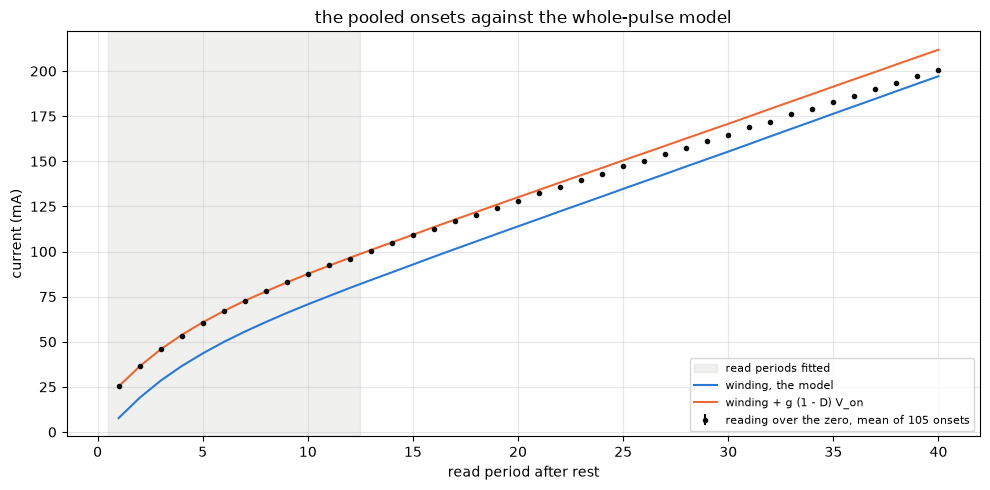

In [15]:
P, f = SETS["pooled"], HEAD["pooled"]
se = P.y.std(axis=0, ddof=1) / np.sqrt(len(P.y)) * P.gain / CPA * 1e3
n = np.arange(ROWS) + 1                 # read period, 1 the first pulse
fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(0.5, READ_PERIODS + 0.5, color=MUTED, alpha=0.12,
           label="read periods fitted")
ax.errorbar(n, f["y"] * 1e3, se, fmt="o", ms=3, color=INK,
            label="reading over the zero, mean of 105 onsets")
ax.plot(n, f["iw"] * 1e3, color=BLUE, label="winding, the model")
ax.plot(n, (f["iw"] + f["g"] * f["x"]) * 1e3, color=ORANGE,
        label="winding + g (1 - D) V_on")
ax.legend(fontsize=8)
figures.label(ax, x="read period after rest", y="current (mA)",
              title="the pooled onsets against the whole-pulse model")
figures.finish(fig)

Over the twelve fitted periods the reading runs 25 to 96 mA and the winding 8 to 80 mA. Past period 12 the model runs over the reading, which is why the fit stops there. The residuals, with each period's standard error over the onsets.

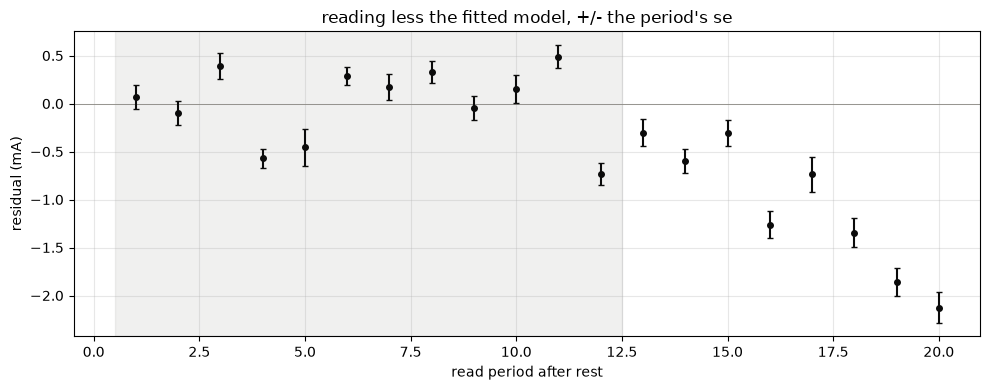

read periods 1 to 12: residual -0.73 to +0.49 mA, largest 6.4 sigma of a period's mean, chi2 125 over 9 dof; periods 13 to 20 -2.1 to -0.3 mA


In [16]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.axhline(0, color=MUTED, lw=0.6)
ax.axvspan(0.5, READ_PERIODS + 0.5, color=MUTED, alpha=0.12)
ax.errorbar(n[:20], f["res"][:20] * 1e3, se[:20], fmt="o", ms=4,
            color=INK, capsize=2)
figures.label(ax, x="read period after rest", y="residual (mA)",
              title="reading less the fitted model, +/- the period's se")
figures.finish(fig)
band = f["res"][:READ_PERIODS] * 1e3
chi2 = ((band / se[:READ_PERIODS]) ** 2).sum()
print(f"read periods 1 to {READ_PERIODS}: residual {band.min():+.2f} to "
      f"{band.max():+.2f} mA, largest {np.abs(band / se[:12]).max():.1f} "
      f"sigma of a period's mean, chi2 {chi2:.0f} over 9 dof; periods 13 "
      f"to 20 {f['res'][12:20].min() * 1e3:+.1f} to "
      f"{f['res'][12:20].max() * 1e3:+.1f} mA")

The residuals stay within 0.73 mA over the fitted band, but at up to 6.4 standard errors of a period's mean, and the chi2 is 125 over 9 degrees of freedom. One $L$ and one $R$ do not describe the chain at the half milliamp level. Past period 12 the model runs 0.3 to 2.1 mA over the reading.

Where the fitted rows sit on the converter. Stage 1's wide-codes result lists the codes the ADC holds over a wider span than one count.

In [17]:
WIDE = results.read("1-board", "wide-codes", BOARD_KEY)["wide_codes"]
STUCK = sorted(int(w["stuck_code"]) for w in WIDE)   # stage 1's wide codes
raw = pd.concat([CAT[n][0] for n in P.names])
raw = raw[raw.ok & (raw.k >= 0) & (raw.k < READ_PERIODS)]["current_raw"]
print(f"fitted rows' raw codes {raw.min()} to {raw.max()}; stage 1's stuck "
      f"codes there: {[c for c in STUCK if raw.min() <= c <= raw.max()]}")
print(f"rows reading a stuck code: {int(raw.isin(STUCK).sum())} of "
      f"{len(raw)}; reading 1280 or 1281: {int(raw.isin([1280, 1281]).sum())}")

fitted rows' raw codes 1236 to 1325; stage 1's stuck codes there: [1279]
rows reading a stuck code: 64 of 1260; reading 1280 or 1281: 0


The fitted rows read codes 1236 to 1325. Stage 1's one stuck code in that span, 1279, holds 64 of the 1260 fitted rows, and no row reads 1280 or 1281. A code that holds a span of inputs is one candidate for the residual's pattern, listed with the open discrepancies.

### The statistical error

The onset is the unit of repeat. Its rows move together, so the bootstrap resamples onsets, with replacement inside each direction, and refits each draw.

In [18]:
def bootstrap(s, draws=BOOT, seed=SEED):
    # g over draws of the onsets with replacement within each direction
    rng = np.random.default_rng(seed)
    fw = np.flatnonzero(s.keys.sgn.to_numpy() > 0)
    rv = np.flatnonzero(s.keys.sgn.to_numpy() < 0)
    out = []
    for _ in range(draws):
        idx = np.concatenate([rng.choice(fw, len(fw)),
                              rng.choice(rv, len(rv))])
        out.append(fit(s, s.y[idx].mean(axis=0), s.v_on[idx].mean())["g"])
    return np.asarray(out) * 1e3        # mS


BOOTS = {name: bootstrap(s) for name, s in SETS.items()}
G_STAT = {name: float(pd.Series(b).std()) for name, b in BOOTS.items()}
for name, b in BOOTS.items():
    lo, hi = np.quantile(b, [0.025, 0.975])
    print(f"{name:6s} g {HEAD[name]['g'] * 1e3:.3f} +/- {G_STAT[name]:.3f}"
          f" mS (95 % {lo:.2f} to {hi:.2f})")
d = HEAD["brake"]["g"] - HEAD["A"]["g"]
e = np.hypot(G_STAT["A"], G_STAT["brake"])
print(f"braked less session A: {d * 1e3:+.3f} +/- {e:.3f} mS "
      f"({d * 1e3 / e:+.1f} sigma)")

A      g 3.865 +/- 0.061 mS (95 % 3.72 to 3.97)
brake  g 3.804 +/- 0.054 mS (95 % 3.69 to 3.90)
pooled g 3.806 +/- 0.042 mS (95 % 3.74 to 3.90)
braked less session A: -0.061 +/- 0.082 mS (-0.7 sigma)


The pooled value is 3.806 +/- 0.042 mS. The braked session reads 0.061 +/- 0.082 mS under session A, inside one sigma. A coast of 3 ms and a coast of 500 ms before the onset give the same $g$.

### By onset and by direction

With $L$ and $R$ held at the pooled fit, each onset gives $g$ on its own, at its own $V_\mathrm{on}$.

In [19]:
def pinned(s, L, R, y=None, v_on=None):
    # g alone at each profile (default every onset), L and R held
    y = s.y if y is None else y
    v_on = s.v_on if v_on is None else v_on
    F = wt.pulse_train(s.h, np.array([L]), np.array([R]), *s.lags,
                       SAMPLE, ARR, HZ, R_BRAKE)[:, 0]
    ks = slice(0, READ_PERIODS)
    x = (1 - s.h / ARR)[ks]             # the lever per volt
    r = y[:, ks] * s.gain[ks] / CPA - np.outer(v_on, F[ks])
    return (r @ x) / (x @ x) / v_on     # S, one a profile


PER = SETS["pooled"].keys.copy()
PER["session"] = PER.cap.str.split("/").str[0]
PER["g_ms"] = pinned(SETS["pooled"], HEAD["pooled"]["L"],
                     HEAD["pooled"]["R"]) * 1e3
stats = PER.groupby(["session", "sgn"])["g_ms"].agg(
    ["size", "mean", "std", "sem"])
print(stats.to_string(float_format=lambda v: f"{v:.3f}"))
by_dir = PER.groupby("sgn")["g_ms"].agg(["mean", "sem"])
DIR_PIN = by_dir.loc[1, "mean"] - by_dir.loc[-1, "mean"]
DIR_PIN_SE = np.hypot(by_dir.loc[1, "sem"], by_dir.loc[-1, "sem"])
P = SETS["pooled"]
lever = (1 - P.h[0] / ARR) * P.v_on.mean()   # V, at read period 1
rows_sd = np.sqrt((P.y[:, :12].std(axis=0, ddof=1) ** 2).mean()) / CPA
alone = rows_sd / np.linalg.norm((1 - P.h[:12] / ARR) * P.v_on.mean())
print(f"forward less reverse, L and R pinned: {DIR_PIN:+.3f} +/- "
      f"{DIR_PIN_SE:.3f} mS ({DIR_PIN / DIR_PIN_SE:+.1f} sigma), "
      f"{DIR_PIN * lever:+.2f} mA at read period 1")
print(f"per-onset sd {PER.g_ms.std():.3f} mS against "
      f"{alone * 1e3:.3f} if an onset's rows were independent")
low = PER.loc[PER.g_ms.idxmin()]
print(f"lowest onset {low.cap} segment {low.onset} ({low.sgn:+d}): "
      f"{low.g_ms:.2f} mS, the next lowest {PER.g_ms.nsmallest(2).iloc[1]:.2f}")

             size  mean   std   sem
session sgn                        
A       -1     26 3.916 0.139 0.027
         1     26 3.758 0.213 0.042
brake   -1     27 3.848 0.129 0.025
         1     26 3.702 0.152 0.030
forward less reverse, L and R pinned: -0.151 +/- 0.032 mS (-4.8 sigma), -0.70 mA at read period 1
per-onset sd 0.179 mS against 0.083 if an onset's rows were independent
lowest onset A/ol-1 segment 5 (+1): 2.91 mS, the next lowest 3.50


Each group's onsets, with the group's mean and standard error. The thing to see is the two sessions agreeing direction for direction, the forward onsets sitting under the reverse ones in both, and the meter's value above every group.

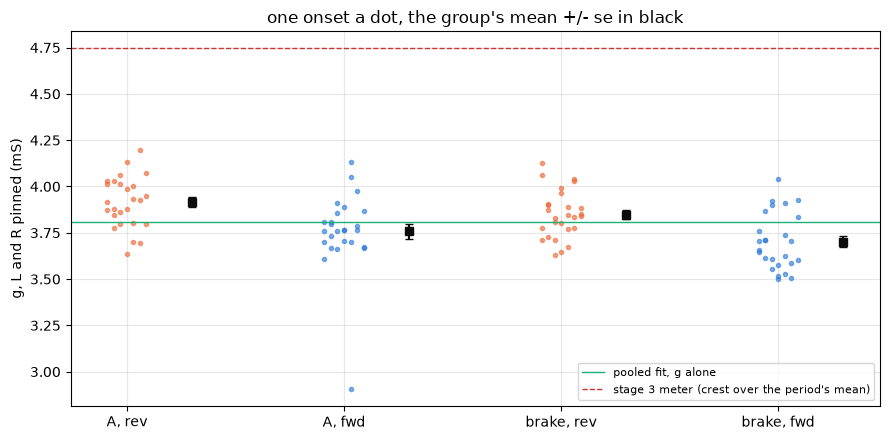

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, ((sess, sgn), grp) in enumerate(PER.groupby(["session", "sgn"])):
    jitter = (np.arange(len(grp)) % 7 - 3) * 0.03
    color = BLUE if sgn > 0 else ORANGE
    ax.plot(i + jitter, grp.g_ms, ".", color=color, alpha=0.6)
    ax.errorbar(i + 0.3, grp.g_ms.mean(), grp.g_ms.sem(), fmt="s",
                color=INK, capsize=3)
ax.axhline(HEAD["pooled"]["g"] * 1e3, color=GREEN, lw=1,
           label="pooled fit, g alone")
ax.axhline(G_METER["value"], color=RED, ls="--", lw=1,
           label="stage 3 meter (crest over the period's mean)")
ax.set_xticks(range(4), [f"{s}, {'fwd' if d > 0 else 'rev'}" for s, d in
                         stats.index])
ax.legend(fontsize=8)
figures.label(ax, y="g, L and R pinned (mS)",
              title="one onset a dot, the group's mean +/- se in black")
figures.finish(fig)

Forward reads 0.151 +/- 0.032 mS under reverse with $L$ and $R$ pinned, 4.8 sigma, and in both sessions. That is 0.70 mA at the first read period, inside stage 1's direction offset of the current chain, 1.21 counts (0.30 to 2.17), about 1.1 mA. A chain offset by direction is the likely reading, not the motor's term. The per-onset sd, 0.179 mS, is twice the 0.083 mS that independent rows would give, which is why the onset is the unit of repeat. One forward onset of session A, sweep 1's segment 5, sits at 2.91 mS, 0.6 mS under the next lowest. It passes every gate and is kept. A contact state at that rotor angle is one possible reading, untested.

### The refusal rules

A fit is refused when its per-period rms is over 1 mA, its $L/R$ is outside 2 to 8 PWM periods, its directions differ by more than 0.4 mS, its groups of session and direction spread by more than 0.4 mS sd, or the field it gives breaks the product bound $0 < g_\mathrm{q016}\,r_\mathrm{q12} \le 2^{25}$. Each number first.

In [21]:
def by(s, sel, f0):
    # g of a subset's mean profile: free, and with L and R held at f0's
    y, v = s.y[sel].mean(axis=0), s.v_on[sel].mean()
    g_pin = pinned(s, f0["L"], f0["R"], y[None, :], np.array([v]))[0]
    return fit(s, y, v)["g"] * 1e3, g_pin * 1e3


P, H0 = SETS["pooled"], HEAD["pooled"]
sgn = P.keys.sgn.to_numpy()
cells = {"session": P.keys.cap.str.split("/").str[0].to_numpy(),
         "sweep": P.keys.cap.to_numpy()}
(fw_free, fw_pin), (rv_free, rv_pin) = (by(P, sgn == d, H0) for d in (1, -1))
DIR_FREE, DIR_GROUP_PIN = fw_free - rv_free, fw_pin - rv_pin
SD = {}
for label, of in cells.items():
    g = [by(P, (of == b) & (sgn == d), H0) for b in np.unique(of)
         for d in (1, -1)]
    SD[label] = (np.std([a for a, _ in g], ddof=1),
                 np.std([b for _, b in g], ddof=1), len(g))
TAU_PERIODS = H0["L"] / H0["R"] * HZ
print(f"rms {H0['rms'] * 1e3:.2f} mA; L/R {TAU_PERIODS:.2f} periods; "
      f"forward less reverse, free {DIR_FREE:+.2f}, pinned "
      f"{DIR_GROUP_PIN:+.2f} mS")
for label, (free, pin, n) in SD.items():
    print(f"sd over the {n} {label}-directions: free {free:.2f}, pinned "
          f"{pin:.2f} mS")

rms 0.44 mA; L/R 3.61 periods; forward less reverse, free -0.18, pinned -0.15 mS
sd over the 4 session-directions: free 0.10, pinned 0.09 mS
sd over the 12 sweep-directions: free 0.17, pinned 0.09 mS


### The sample's lateness and the field

The sample closes after the window's middle, by the shunt's 31 ticks less the middle of the model's window, $(t_\mathrm{on} + t_\mathrm{off})/2$. In a settled period the current rises through the window at $(1 - D)\,V_\mathrm{on}/L$ per second, so the sample sits over the period's mean by that rate times the lateness, the same $(1 - D)\,V_\mathrm{on}$ form with a conductance of the lateness over $L$. The field holds the sum, in Q0.16 counts of shunt per tap count, on stage 1's two scales.

In [22]:
def lateness(s, f, lags=None, sample=SAMPLE):
    # mS on (1 - D) V_on: the sample's place after the window's middle
    on, off = s.lags if lags is None else lags
    middle = (on + off) / 2
    return (sample - middle) * wt.tick_seconds(ARR, HZ) / f["L"] * 1e3


LATE = {name: lateness(SETS[name], f) for name, f in HEAD.items()}
G_MEAN = {name: HEAD[name]["g"] * 1e3 + LATE[name] for name in HEAD}
Q016_PER_MS = CPA / VPV * 65536 / 1e3   # field counts a mS on the scales
FIELD = {name: round(G_MEAN[name] * Q016_PER_MS) for name in HEAD}
for name in HEAD:
    print(f"{name:6s} g {HEAD[name]['g'] * 1e3:.3f} + lateness "
          f"{LATE[name]:.3f} = {G_MEAN[name]:.3f} mS -> g_window_q016 "
          f"{FIELD[name]} ({G_MEAN[name] * Q016_PER_MS:.2f})")
print(f"1 mS is {Q016_PER_MS:.1f} counts of the field")

A      g 3.865 + lateness 0.126 = 3.991 mS -> g_window_q016 1195 (1195.33)
brake  g 3.804 + lateness 0.125 = 3.928 mS -> g_window_q016 1177 (1176.56)
pooled g 3.806 + lateness 0.126 = 3.933 mS -> g_window_q016 1178 (1177.78)
1 mS is 299.5 counts of the field


The pooled fit with its lateness is 3.933 mS, `g_window_q016` 1178 (1177.78 before rounding). Session A alone would give 1195 and the braked session 1177. The rules, on the pooled fit and the field it gives.

In [23]:
R_Q12 = {c["meta"]["drive"]["r_q12"] for _, c in ALL}
assert len(R_Q12) == 1, R_Q12           # one servo, one r_q12
R_Q12 = R_Q12.pop()
fence = FIELD["pooled"] * R_Q12
CHECKS = {
    "per-period rms <= 1 mA": H0["rms"] * 1e3 <= 1.0,
    "L/R inside 2 to 8 periods": 2 <= TAU_PERIODS <= 8,
    "directions within 0.4 mS":
        max(abs(DIR_GROUP_PIN), abs(DIR_FREE)) <= 0.4,
    "session-direction sd <= 0.4 mS":
        max(SD["session"][:2] + SD["sweep"][:2]) <= 0.4,
    "fence 0 < g_window_q016 x r_q12 <= 2^25": 0 < fence <= FENCE}
for rule, ok in CHECKS.items():
    print(f"{'PASS' if ok else 'FAIL'}  {rule}")
print(f"fence: {FIELD['pooled']} x {R_Q12} = {fence} = "
      f"{fence / FENCE:.3f} of 2^25")

PASS  per-period rms <= 1 mA
PASS  L/R inside 2 to 8 periods
PASS  directions within 0.4 mS
PASS  session-direction sd <= 0.4 mS
PASS  fence 0 < g_window_q016 x r_q12 <= 2^25
fence: 1178 x 3725 = 4388050 = 0.131 of 2^25


All five pass. The servo's `r_q12` comes from the sweeps' meta, 3725 in all six.

### The model's choices

The edges, the sample's instant and the fitted window are choices the fit depends on. Each moved alone, with the lateness recomputed at the moved edges and sample.

In [24]:
(ON_LO, OFF_HI), (ON_HI, OFF_LO) = (edges(P.rail, "lo", "hi"),
                                    edges(P.rail, "hi", "lo"))
ym, vm = P.y.mean(axis=0), P.v_on.mean()
mid = sum(P.lags) / 2                   # the model window's middle, ticks
CHOICES = {"ON edge low": dict(lags=(ON_LO, P.lags[1])),
           "ON edge high": dict(lags=(ON_HI, P.lags[1])),
           "OFF edge low": dict(lags=(P.lags[0], OFF_LO)),
           "OFF edge high": dict(lags=(P.lags[0], OFF_HI)),
           "sample at the window's middle": dict(sample=mid)}
rows = []
for name, kw in CHOICES.items():
    f = fit(P, ym, vm, F=grid(P, **kw))
    late = lateness(P, f, kw.get("lags"), kw.get("sample", SAMPLE))
    rows.append((name, f["g"] * 1e3, late, f["rms"] * 1e3))
for first, last in ((1, 12), (0, 8), (0, 16)):
    f = fit(P, ym, vm, first=first, rows=last)
    rows.append((f"read periods {first + 1} to {last}", f["g"] * 1e3,
                 lateness(P, f), f["rms"] * 1e3))
CH = pd.DataFrame(rows, columns=["choice", "g_ms", "late_ms", "rms_ma"])
CH["g_over_mean_ms"] = CH.g_ms + CH.late_ms
print(CH.to_string(index=False, float_format=lambda v: f"{v:.2f}"))
print(f"g alone {CH.g_ms.min():.2f} to {CH.g_ms.max():.2f} mS, g plus "
      f"the lateness {CH.g_over_mean_ms.min():.2f} to "
      f"{CH.g_over_mean_ms.max():.2f} mS")

                       choice  g_ms  late_ms  rms_ma  g_over_mean_ms
                  ON edge low  3.73     0.26    0.41            3.99
                 ON edge high  3.93    -0.08    0.51            3.85
                 OFF edge low  3.62     0.27    0.47            3.88
                OFF edge high  4.05    -0.05    0.41            4.00
sample at the window's middle  3.94     0.00    0.44            3.94
         read periods 2 to 12  3.80     0.13    0.46            3.93
          read periods 1 to 8  3.91     0.12    0.38            4.03
         read periods 1 to 16  3.79     0.13    0.46            3.92
g alone 3.62 to 4.05 mS, g plus the lateness 3.85 to 4.03 mS


$g$ alone moves 3.62 to 4.05 mS over these choices, $g$ plus the lateness only 3.85 to 4.03. The sum is the better measured number, since a sample placed at the window's middle estimates it directly and the edges move $g$ and the lateness the opposite way.

### What the rows cannot see

Nothing samples the first pulse's rising edge. A first pulse that starts late leaves a deficit that decays at $L/R$, and a free $L$ and $R$ absorb most of it. The same fit, with the first pulse after rest starting late by a number of ticks.

In [25]:
SCAN = []
for x in LATE_TICKS:
    f = fit(P, ym, vm, F=grid(P, first_late=x))
    SCAN.append((x, f["g"] * 1e3, f["rms"] * 1e3))
SCAN = pd.DataFrame(SCAN, columns=["late_ticks", "g_ms", "rms_ma"])
SLOPE = np.polyfit(SCAN.late_ticks, SCAN.g_ms, 1)[0]
meter_alone = G_METER["value"] - LATE["pooled"]   # like for like
print(SCAN.T.to_string(header=False, float_format=lambda v: f"{v:.2f}"))
print(f"{SLOPE:+.3f} mS a tick of lateness; the meter's g less the "
      f"lateness, {meter_alone:.2f} mS, is this fit with the first pulse "
      f"{np.interp(meter_alone, SCAN.g_ms, SCAN.late_ticks):.0f} ticks "
      f"late")
d = (HEAD["brake"]["g"] - HEAD["A"]["g"]) * 1e3
e = np.hypot(G_STAT["A"], G_STAT["brake"])
print(f"braked less session A in lateness: {d / SLOPE:+.1f} +/- "
      f"{e / SLOPE:.1f} ticks")

late_ticks 0.00 5.00 10.00 15.00 20.00 25.00 30.00 35.00 40.00
g_ms       3.81 3.99  4.14  4.32  4.49  4.58  4.75  4.86  5.02
rms_ma     0.44 0.43  0.43  0.42  0.42  0.42  0.41  0.41  0.41
+0.030 mS a tick of lateness; the meter's g less the lateness, 4.62 mS, is this fit with the first pulse 26 ticks late
braked less session A in lateness: -2.1 +/- 2.7 ticks


The fit's $g$ against the first pulse's lateness, with the meter's value less this lateness, like for like. The thing to see is $g$ climbing 0.030 mS a tick while the rms stays flat, so the rows do not choose.

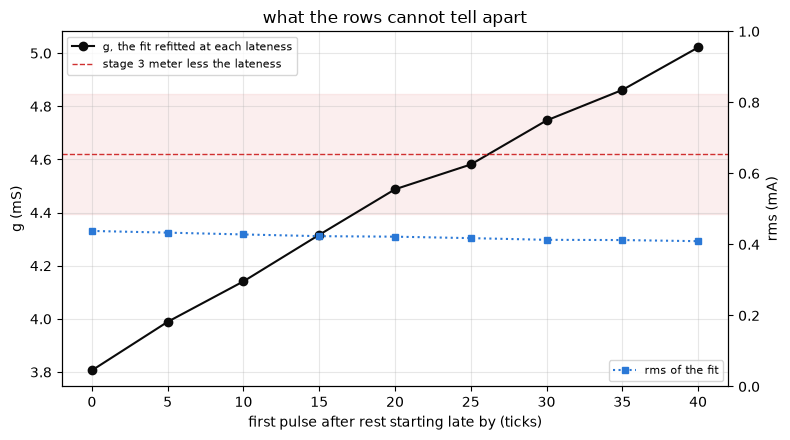

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(SCAN.late_ticks, SCAN.g_ms, "o-", color=INK,
        label="g, the fit refitted at each lateness")
ax.axhline(meter_alone, color=RED, ls="--", lw=1,
           label="stage 3 meter less the lateness")
ax.axhspan(G_METER["lo"] - LATE["pooled"], G_METER["hi"] - LATE["pooled"],
           color=RED, alpha=0.08)
ax2 = ax.twinx()
ax2.plot(SCAN.late_ticks, SCAN.rms_ma, "s:", color=BLUE, ms=4,
         label="rms of the fit")
ax2.set_ylim(0, 1)
ax2.set_ylabel("rms (mA)")
ax.legend(fontsize=8, loc="upper left")
ax2.legend(fontsize=8, loc="lower right")
figures.label(ax, x="first pulse after rest starting late by (ticks)",
              y="g (mS)", title="what the rows cannot tell apart")
figures.finish(fig)

The meter's value is this fit with a first pulse 26 ticks late. The rows say the fit's $g$ holds only as far as the first pulse after rest is an ordinary one, and that it can be too low by this, not too high. The braked repeat narrowed it. In lateness the two sessions differ by -2.1 +/- 2.7 ticks, so a lateness that grows with the coast's length from 3 to 500 ms is ruled out to about 3 ticks. A fixed lateness after any release from coast is untested, since both sessions leave a coast.

## Results

$g$ alone is 3.806 +/- 0.042 mS over 105 onsets of two sessions, $L$ 0.79 mH, $R$ 4.38 ohm, rms 0.44 mA. With the sample's lateness, 0.126 mS, the term over the period's mean is 3.933 +/- 0.042 mS, and `g_window_q016` 1178 on stage 1's scales. The result file's quantities.

In [27]:
q, pm = results.quantity, results.pm
OUT = {
    "g_over_mean_ms": pm(G_MEAN["pooled"], G_STAT["pooled"], "mS, the "
                         "window term the reading carries over the "
                         "period's mean, g alone plus the sample's "
                         "lateness, on (1 - D) V_on; bounds the bootstrap "
                         "sd of g over the 105 onsets"),
    "g_ms": pm(H0["g"] * 1e3, G_STAT["pooled"], "mS, g alone at the "
               "shunt sample's instant, bootstrap sd over onsets"),
    "lateness_ms": q(LATE["pooled"], unit="mS, the sample's place after "
                     "the window's middle at the fit's L"),
    "g_choices_ms": q(H0["g"] * 1e3, CH.g_ms.min(), CH.g_ms.max(), "mS, "
                      "g alone with the edges, the sample and the window "
                      "moved one at a time, the range as bounds"),
    "g_over_mean_choices_ms": q(G_MEAN["pooled"], CH.g_over_mean_ms.min(),
                                CH.g_over_mean_ms.max(), "mS, the same "
                                "for g plus the lateness"),
    "l_mh": q(H0["L"] * 1e3, unit="mH, the fit's L, grid step 0.01"),
    "r_ohm": q(H0["R"], unit="ohm, the fit's R, grid step 0.02"),
    "tau_periods": q(TAU_PERIODS, unit="PWM periods, the fit's L/R"),
    "rms_ma": q(H0["rms"] * 1e3, unit="mA, residual rms over read "
                "periods 1 to 12, 9 dof"),
    "v_on_v": q(P.v_on.mean(), unit="V, the on-window volts, mean"),
    "n_onsets": q(len(P.y), unit="onsets fitted"),
}

In [28]:
for name in ("A", "brake"):
    OUT[f"g_ms_{name}"] = pm(HEAD[name]["g"] * 1e3, G_STAT[name], "mS, "
                             "the same fit on this session alone")
    OUT[f"g_over_mean_ms_{name}"] = q(G_MEAN[name], unit="mS, its g plus "
                                      "its lateness")
OUT["forward_less_reverse_ms"] = pm(DIR_PIN, DIR_PIN_SE, "mS, per-onset "
                                    "g with L and R pinned, forward less "
                                    "reverse, se")
OUT["first_pulse_slope_ms_per_tick"] = q(SLOPE, unit="mS a tick the first "
                                         "pulse after rest starts late")
OUT["meter_less_lateness_ms"] = q(meter_alone, unit="mS, stage 3's meter "
                                  "g less this lateness, like for like")
OUT["fence"] = q(fence / FENCE, unit="g_window_q016 x r_q12 over 2^25 at "
                 "the field this value gives")
OUT["checks"] = {rule: bool(ok) for rule, ok in CHECKS.items()}

### The result file

The notes that define every key, then the file as written.

In [29]:
NOTES = (
    "stage 3 window term of mg90-d on dev-v006-2A-D, horn free, 5 V, the "
    "OpenLoop onsets from rest of window-term/onsets-A (each after 500 ms "
    "of coast) and window-term/onsets-A-brake (each after a 300 ms brake "
    "released about 3 ms before), 25 / 27 / 29 % both ways, gated and "
    "fitted together. The reading over each onset's own trough zero, the "
    "board's settle gain by the row's width, is fitted over read periods "
    "1 to 12 as the winding current of a whole-pulse train (stage 1's "
    "edges at the sweeps' rail, sample instant and low-side loop; L and R "
    "free on a grid) plus g x (1 - D) x V_on. g_over_mean_ms is the "
    "quantity the field holds, g plus the sample's lateness, in mS; the "
    "field is g_over_mean_ms x counts_per_a / terminal_counts_per_v x "
    "65536 on stage 1's scales. Bounds are the bootstrap sd over onsets "
    "(2000 draws within direction, seeded) unless the unit says otherwise."
    " The fit cannot tell g from a first pulse that starts late "
    "(first_pulse_slope_ms_per_tick): g is good only as far as the first "
    "pulse after rest is an ordinary one."
)
CAPTURE = ", ".join(str(results.rel(p.parent)) for p in
                    (SESSIONS["A"][0], SESSIONS["brake"][0]))
path = results.write("3-servo", "window-term", CAPTURE, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("3-servo", "window-term", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys")
flat = pd.DataFrame([{"key": k, **v} for k, v in written.items()
                     if isinstance(v, dict) and "value" in v])
show(flat, n=None)

wrote stages/3-servo/window-term/results/mg90-d__dev-v006-2A-D.json with 20 keys


,key,value,lo,hi,unit
0,g_over_mean_ms,3.933,3.891,3.974,"mS, the window term the reading carries over t..."
1,g_ms,3.806,3.765,3.848,"mS, g alone at the shunt sample's instant, boo..."
2,lateness_ms,0.126,NaN,NaN,"mS, the sample's place after the window's midd..."
3,g_choices_ms,3.806,3.617,4.054,"mS, g alone with the edges, the sample and the..."
4,g_over_mean_choices_ms,3.933,3.853,4.027,"mS, the same for g plus the lateness"
5,l_mh,0.790,NaN,NaN,"mH, the fit's L, grid step 0.01"
6,r_ohm,4.380,NaN,NaN,"ohm, the fit's R, grid step 0.02"
7,tau_periods,3.607,NaN,NaN,"PWM periods, the fit's L/R"
8,rms_ma,0.438,NaN,NaN,"mA, residual rms over read periods 1 to 12, 9 dof"
9,v_on_v,4.875,NaN,NaN,"V, the on-window volts, mean"


## Limitations

- One servo, one rail (4.875 V on the terminals), two sessions 33 minutes apart. Every number is a candidate for another day, another temperature or another rail.
- The onsets run at 6 to 10 % effective duty and 8 to 80 mA of winding current. The meter's levels ran at 16 to 49 % and 230 to 360 mA. The $(1 - D)\,V_\mathrm{on}$ form is what carries one $g$ between them, and these rows do not test it there.
- The model has one $L$ and one $R$. Its residual is 6 standard errors at its worst period, so the chain has structure at the half milliamp level that the model leaves in $g$, $L$ and $R$.
- The sample's lateness is the model's, at the fit's $L$ and stage 1's edges, not a measured one, so the sum stays the one this fit determines.

## Open discrepancies

1. The fit, 3.93 mS over the period's mean, against stage 3's meter, 4.75 (4.52 to 4.97). Candidates are the $(1 - D)\,V_\mathrm{on}$ form not carrying one $g$ from the onsets' duties and currents to the meter's (leading, possible), a fixed lateness of the first pulse after any release from coast of about 26 ticks (possible, low, no mechanism known), and a sample whose effective instant is earlier than stage 1's +31 ticks (possible, low). The same chain with the brake held through to the first pulse, so no onset leaves a coast, separates the second from the others. Under the second $g$ moves toward 4.6, under the others it stays near 3.9. A second shunt sample late in the window, read in the same rows, separates the winding's rise from the term inside one pulse.
2. Forward under reverse by 0.15 mS, in both sessions. Candidates are the current chain's offset by direction, stage 1's 1.2 counts (leading, likely), and a term that differs by direction. The same onsets on the RL dummy, which has no direction of its own, separate them.
3. The residual's structure, 6 standard errors at its worst period. Candidates are the converter's stuck code 1279 inside the fitted rows (leading, possible), a second time constant in the winding or the amplifier, and the brake loop. The same ramp on the RL dummy at the same currents separates the board's part from the motor's.

## Conclusion

On mg90-d at 5 V the window term over the period's mean is 3.93 +/- 0.04 mS, `g_window_q016` 1178 on board 2A-D's stage 1 scales, from 105 onsets of two sessions that agree within one sigma. It is the value a reading taken from rest supports, and it can be low against the meter's 4.75 mS by the fit's one blind spot, a first pulse that starts late. Stage 5's cruise-friction notebook takes it as the field the velocity cruises ran on, and its friction line is good only as this value is.